# 02 — Preparação dos Dados e Desenho Analítico

O notebook 01 descreveu a base do SINASC 2014–2024. Este notebook explica como essa base se transforma na **população analítica** e como são definidos o desfecho **Y**, a exposição **T** e as covariáveis **X**.

Os exemplos numéricos usam 2024. As mesmas regras são aplicadas, separadamente, a cada ano de 2014 a 2024.

In [1]:
from pathlib import Path
import json
import sys

import duckdb
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

# ------------------------------------------------------------
# Raiz do projeto: procurada nos diretórios pais, sem caminho fixo
# ------------------------------------------------------------
cwd = Path.cwd().resolve()
raiz = next(
    (p for p in [cwd, *cwd.parents]
     if (p / "src" / "temporal.py").exists()
     and (p / "docs" / "entrega" / "METADADOS_BASE.md").exists()),
    None,
)
if raiz is None:
    raise FileNotFoundError(f"Raiz do projeto não encontrada a partir de {cwd}")
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

venv_projeto = (raiz / ".venv").resolve()
if Path(sys.prefix).resolve() != venv_projeto:
    print(f"Atenção: o kernel não está usando a .venv do projeto ({venv_projeto}).")

from src.temporal import caminhos_ano
from src.visualizacao import CORES_IPT, aplicar_tema_base, configurar_plotly

configurar_plotly()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

ANOS = list(range(2014, 2025))
TABELAS = raiz / "outputs" / "temporal" / "tabelas"
con = duckdb.connect()


def num(valor, casas=0):
    """Formata número no padrão brasileiro: 1.234.567,89."""
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "§").replace(".", ",").replace("§", ".")


def mostrar(fig, titulo, altura=460, largura=950, margem_esquerda=None):
    """Aplica a identidade visual IPT e exibe a figura."""
    aplicar_tema_base(fig, titulo)
    fig.update_layout(width=largura, height=altura, separators=",.")
    if margem_esquerda is not None:
        fig.update_layout(margin_l=margem_esquerda)
    fig.show()


def formatar(tabela, casas=2):
    """Converte uma tabela numérica para texto no padrão brasileiro."""
    return tabela.map(lambda v: "—" if pd.isna(v) else num(v, casas))


def parquet(ano):
    """Caminho do Parquet anual, já em formato aceito pelo DuckDB."""
    return caminhos_ano(raiz, ano).parquet.as_posix()


print("Raiz do projeto localizada:", raiz.name)

Raiz do projeto localizada: big-data-sinasc-causal-ml


## 1. Do bruto à população analítica

A população analítica é construída por regras aplicadas em sequência:

1. **Mês de início conhecido:** `MESPRENAT` entre 1 e 9, com peso registrado. O código 99 e o campo vazio ficam fora.
2. **Peso válido:** 500 g ≤ `PESO` ≤ 6.000 g.
3. **Gestação única:** `GRAVIDEZ` = 1. O resultado é a **população A**.
4. **Comparador restrito ao 4º–6º mês:** exclui os inícios no 7º–9º mês. O resultado é a **população B**, a principal.
5. **Comparador restrito ao 4º–5º mês:** exclui também o 6º mês. O resultado é a **população C**, usada como sensibilidade.

A consulta abaixo aplica as regras ao arquivo de 2024 com DuckDB.

In [2]:
contagens = con.execute(f"""
    WITH base AS (
        SELECT try_cast(MESPRENAT AS INTEGER) AS mes,
               try_cast(PESO AS INTEGER) AS peso,
               try_cast(GRAVIDEZ AS INTEGER) AS gravidez
        FROM read_parquet('{parquet(2024)}')
    )
    SELECT
        count(*) AS bruto,
        count(*) FILTER (WHERE mes BETWEEN 1 AND 9 AND peso > 0) AS mes_conhecido,
        count(*) FILTER (WHERE mes BETWEEN 1 AND 9 AND peso > 0 AND peso < 500) AS peso_abaixo_500,
        count(*) FILTER (WHERE mes BETWEEN 1 AND 9 AND peso > 6000) AS peso_acima_6000,
        count(*) FILTER (WHERE mes BETWEEN 1 AND 9 AND peso BETWEEN 500 AND 6000) AS peso_valido,
        count(*) FILTER (WHERE mes BETWEEN 1 AND 9 AND peso BETWEEN 500 AND 6000 AND gravidez = 1) AS pop_A,
        count(*) FILTER (WHERE mes BETWEEN 1 AND 6 AND peso BETWEEN 500 AND 6000 AND gravidez = 1) AS pop_B,
        count(*) FILTER (WHERE mes BETWEEN 1 AND 5 AND peso BETWEEN 500 AND 6000 AND gravidez = 1) AS pop_C,
        count(*) FILTER (WHERE mes BETWEEN 1 AND 3 AND peso BETWEEN 500 AND 6000 AND gravidez = 1) AS t1
    FROM base
""").df().iloc[0].astype(int)

etapas = [
    ("Base bruta", "—", contagens.bruto),
    ("Mês de início conhecido", "MESPRENAT 1–9 e peso registrado", contagens.mes_conhecido),
    ("Peso válido", "500 g ≤ PESO ≤ 6.000 g", contagens.peso_valido),
    ("População A", "gestação única (GRAVIDEZ = 1)", contagens.pop_A),
    ("População B", "comparador 4º–6º mês", contagens.pop_B),
    ("População C", "comparador 4º–5º mês", contagens.pop_C),
]
fluxo = pd.DataFrame(etapas, columns=["Etapa", "Regra", "Restantes"])
fluxo["Excluídos"] = (-fluxo.Restantes.diff()).fillna(0).astype(int)
fluxo["% da base bruta"] = 100 * fluxo.Restantes / contagens.bruto

# Conferência com os números consolidados do projeto
fluxo_documentado = json.loads((raiz / "outputs/diagnostics/fase1_amostra.json").read_text(encoding="utf-8"))["fluxo_amostra"]
assert [e["n_restante"] for e in fluxo_documentado[:3]] == list(fluxo.Restantes[1:4])
perfil = pd.read_csv(raiz / "outputs/entrega_1_nacional_aipw/tabelas/tabela1_perfil_base.csv")
perfil = perfil[pd.to_numeric(perfil.ano, errors="coerce").notna()].astype({"ano": int}).set_index("ano")
assert (contagens.pop_B, contagens.pop_C) == (perfil.loc[2024, "n_B"], perfil.loc[2024, "n_C"])

display(fluxo[["Etapa", "Regra", "Excluídos", "Restantes", "% da base bruta"]]
        .assign(Excluídos=lambda t: t.Excluídos.map(lambda v: num(v) if v else "—"),
                Restantes=lambda t: t.Restantes.map(num),
                **{"% da base bruta": lambda t: t["% da base bruta"].map(lambda v: num(v, 2))})
        .set_index("Etapa"))

,Regra,Excluídos,Restantes,% da base bruta
Etapa,,,,
Base bruta,—,—,2.389.325,"100,00"
Mês de início conhecido,MESPRENAT 1–9 e peso registrado,81.079,2.308.246,"96,61"
Peso válido,500 g ≤ PESO ≤ 6.000 g,3.471,2.304.775,"96,46"
População A,gestação única (GRAVIDEZ = 1),53.205,2.251.570,"94,23"
População B,comparador 4º–6º mês,44.356,2.207.214,"92,38"
População C,comparador 4º–5º mês,42.020,2.165.194,"90,62"


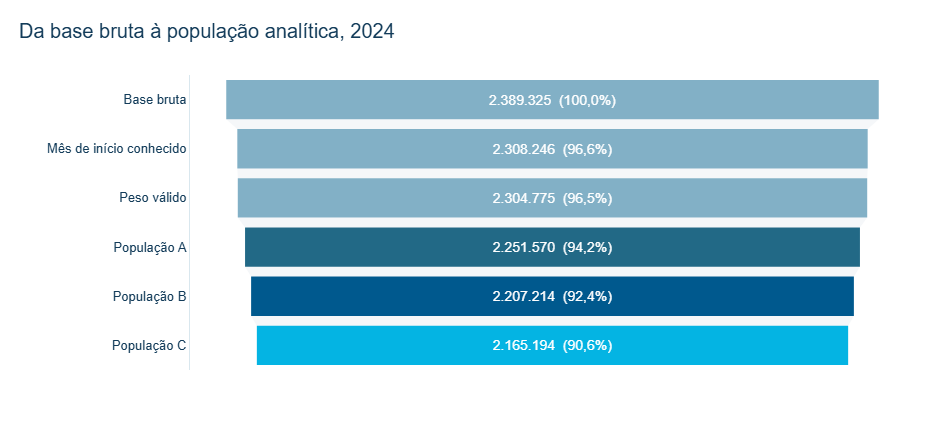

In [3]:
cores_funil = [CORES_IPT["AZUL_CLARO"]] * 3 + [CORES_IPT["AZUL_MEDIO"], CORES_IPT["AZUL_PRINCIPAL"], CORES_IPT["CIANO"]]
fig = go.Figure(go.Funnel(
    y=fluxo.Etapa, x=fluxo.Restantes, marker_color=cores_funil,
    text=[f"{num(v)}  ({num(p, 1)}%)" for v, p in zip(fluxo.Restantes, fluxo["% da base bruta"])],
    textinfo="text", textfont=dict(color="white", size=14),
    connector=dict(fillcolor=CORES_IPT["CINZA_FUNDO"], line=dict(width=0)),
))
fig.update_yaxes(categoryorder="array", categoryarray=list(fluxo.Etapa))
mostrar(fig, "Da base bruta à população analítica, 2024", altura=430, margem_esquerda=190)

As três primeiras regras são de **qualidade e elegibilidade**. Elas retiram registros sem informação utilizável (mês de início desconhecido, peso ausente ou implausível) ou fora da população-alvo (gestações múltiplas).

As duas últimas etapas são de outra natureza. B e C não "limpam" dados: elas **restringem o grupo de comparação**, pelos motivos explicados nas seções 3 e 4.

As sete covariáveis X não removem registros. Valores ausentes viram a categoria "Ignorado".

## 2. Desfecho Y

$$
Y_i =
\begin{cases}
1, & \text{se } \texttt{PESO}_i < 2.500\ \text{g (baixo peso ao nascer)}\\
0, & \text{se } \texttt{PESO}_i \geq 2.500\ \text{g}
\end{cases}
$$

**Por que restringir o peso a 500–6.000 g?** Valores fora dessa faixa são biologicamente implausíveis para um nascido vivo registrado ou indicam erro de digitação. A faixa é uma **regra de qualidade do projeto**, e não parte da definição da OMS.

O baixo peso é definido pela OMS **independentemente da idade gestacional**. Por isso a análise não se restringe a nascimentos a termo.

In [4]:
fora_da_faixa = contagens.peso_abaixo_500 + contagens.peso_acima_6000
assert fora_da_faixa == contagens.mes_conhecido - contagens.peso_valido == 3_471
print(f"2024: {num(contagens.peso_abaixo_500)} registros abaixo de 500 g e {num(contagens.peso_acima_6000)} acima de 6.000 g "
      f"= {num(fora_da_faixa)} excluídos ({num(100 * fora_da_faixa / contagens.mes_conhecido, 2)}% dos registros com mês conhecido).")

2024: 3.416 registros abaixo de 500 g e 55 acima de 6.000 g = 3.471 excluídos (0,15% dos registros com mês conhecido).


## 3. Exposição T: três formulações

A exposição é o **momento de início do pré-natal** (`MESPRENAT`). Em todas as formulações, T = 1 é o início no 1º–3º mês. O que muda é o grupo de comparação (T = 0).

| Formulação | T = 1 | T = 0 | Papel |
| --- | --- | --- | --- |
| **B** | 1º–3º mês | **4º–6º mês** | **análise principal** |
| C | 1º–3º mês | 4º–5º mês | sensibilidade |
| A | 1º–3º mês | 4º–9º mês | referência histórica |

- T = 0 significa **início mais tardio**, e não ausência de pré-natal.
- Registros com mês desconhecido (99 ou vazio) ficam fora de T e não são reclassificados.

In [5]:
formulacoes = pd.DataFrame({
    "Formulação": ["B (principal)", "C (sensibilidade)", "A (referência histórica)"],
    "T = 0": ["4º–6º mês", "4º–5º mês", "4º–9º mês"],
    "N": [contagens.pop_B, contagens.pop_C, contagens.pop_A],
}).set_index("Formulação")
formulacoes["T = 1"] = contagens.t1
formulacoes["N com T = 0"] = formulacoes.N - formulacoes["T = 1"]
formulacoes["% T = 1"] = 100 * formulacoes["T = 1"] / formulacoes.N

assert formulacoes.loc["B (principal)", "N com T = 0"] == 265_169
display(formulacoes.assign(**{col: formulacoes[col].map(num) for col in ("N", "T = 1", "N com T = 0")},
                           **{"% T = 1": formulacoes["% T = 1"].map(lambda v: num(v, 2))})
        [["T = 0", "N", "T = 1", "N com T = 0", "% T = 1"]])

,T = 0,N,T = 1,N com T = 0,% T = 1
Formulação,,,,,
B (principal),4º–6º mês,2.207.214,1.942.045,265.169,"87,99"
C (sensibilidade),4º–5º mês,2.165.194,1.942.045,223.149,"89,69"
A (referência histórica),4º–9º mês,2.251.570,1.942.045,309.525,"86,25"


Em 2024, o grupo T = 1 tem 1.942.045 nascidos vivos nas três formulações. Só o tamanho e a composição do grupo de comparação mudam.

## 4. Por que a formulação A foi revisada?

O mês de início do pré-natal só é conhecido **no nascimento**, quando a DNV é preenchida. Daí surge um problema de tempo:

> Para ser classificada como "início no 7º mês", a gestante precisa **ainda estar grávida no 7º mês**.

Uma gestação que termina antes do 7º mês **nunca** pode aparecer como início no 7º, 8º ou 9º mês. Quanto mais tardio o mês usado para classificar o início, mais tempo a gestação precisa permanecer em curso para que aquele nascimento possa pertencer à categoria. Assim, os meses finais do comparador 4º–9º da formulação A só aceitam gestações que duraram bastante.

As gestações curtas (partos prematuros) concentram grande parte do baixo peso. Por isso, o comparador muito tardio fica artificialmente "protegido" contra o desfecho. É uma **ameaça temporal**: ela distorce a comparação sem ter relação com o efeito do pré-natal.

A figura abaixo é **conceitual**. As barras superiores representam gestações de duração curta, intermediária e mais longa. As inferiores mostram os meses que formam T = 1 e T = 0 em cada formulação.

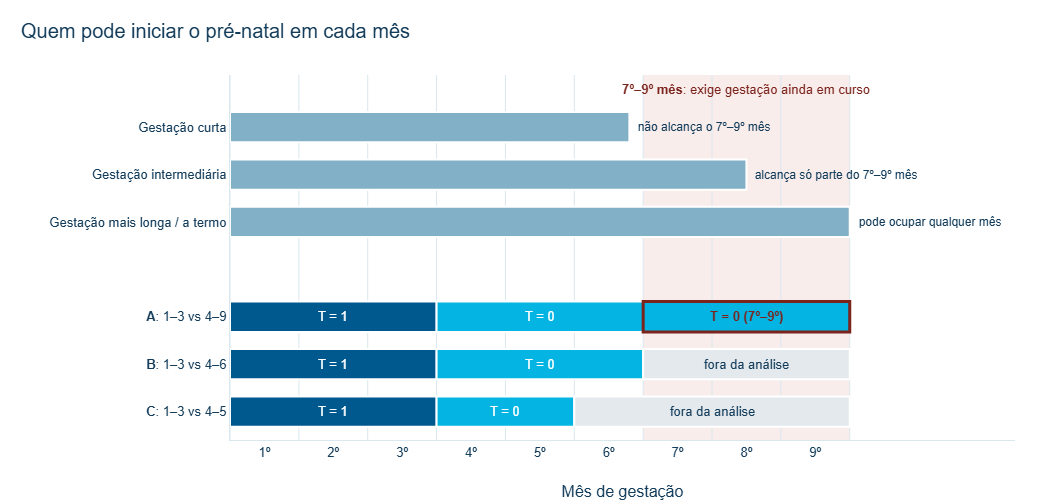

In [6]:
COR_T1, COR_T0, COR_FORA = CORES_IPT["AZUL_PRINCIPAL"], CORES_IPT["CIANO"], "#E4E9EE"

fig = go.Figure(go.Scatter(x=[0, 9.6], y=[0.4, 7.6], mode="markers", marker_opacity=0,
                           showlegend=False, hoverinfo="skip"))
fig.add_vrect(x0=6, x1=9, fillcolor="#F2D7D5", opacity=0.45, line_width=0, layer="below")
fig.add_annotation(x=7.5, y=7.8, text="<b>7º–9º mês</b>: exige gestação ainda em curso",
                   showarrow=False, font=dict(size=13, color="#7B241C"))


def bloco(x0, x1, y, cor, texto="", cor_texto="white", borda="white"):
    fig.add_shape(type="rect", x0=x0, x1=x1, y0=y - 0.32, y1=y + 0.32, fillcolor=cor,
                  line=dict(color=borda, width=2 if borda == "white" else 3))
    if texto:
        fig.add_annotation(x=(x0 + x1) / 2, y=y, text=texto, showarrow=False,
                           font=dict(color=cor_texto, size=13))


# Gestações conceituais (barras superiores): duração em meses, sem equivalência em semanas
gestacoes = [
    (5.8, 7, "não alcança o 7º–9º mês"),
    (7.5, 6, "alcança só parte do 7º–9º mês"),
    (9.0, 5, "pode ocupar qualquer mês"),
]
for fim, y, texto in gestacoes:
    bloco(0, fim, y, CORES_IPT["AZUL_CLARO"])
    fig.add_annotation(x=fim, y=y, text=f"  {texto}", showarrow=False,
                       xanchor="left", font=dict(size=12))

# Formulações (barras inferiores); a faixa 7º–9º da formulação A recebe destaque
COR_DESTAQUE = "#7B241C"
bloco(0, 3, 3, COR_T1, "T = 1")
bloco(3, 6, 3, COR_T0, "T = 0")
bloco(6, 9, 3, COR_T0, "<b>T = 0 (7º–9º)</b>", cor_texto=COR_DESTAQUE, borda=COR_DESTAQUE)
for fim_t0, y in ((6, 2), (5, 1)):
    bloco(0, 3, y, COR_T1, "T = 1")
    bloco(3, fim_t0, y, COR_T0, "T = 0")
    bloco(fim_t0, 9, y, COR_FORA, "fora da análise", cor_texto=CORES_IPT["AZUL_ESCURO"])

fig.update_yaxes(tickvals=[7, 6, 5, 3, 2, 1],
                 ticktext=["Gestação curta", "Gestação intermediária", "Gestação mais longa / a termo",
                           "<b>A</b>: 1–3 vs 4–9", "<b>B</b>: 1–3 vs 4–6", "<b>C</b>: 1–3 vs 4–5"],
                 range=[0.4, 8.1], showgrid=False)
fig.update_xaxes(tickvals=[m - 0.5 for m in range(1, 10)], ticktext=[f"{m}º" for m in range(1, 10)],
                 range=[0, 11.4], title="Mês de gestação", showgrid=False)
for limite in range(0, 10):
    fig.add_vline(x=limite, line_color=CORES_IPT["CINZA_GRADE"], line_width=1, layer="below")
mostrar(fig, "Quem pode iniciar o pré-natal em cada mês", altura=500, largura=1050, margem_esquerda=230)

- A gestação **curta** termina antes da faixa do 7º–9º mês: só poderia estar em T = 1 ou no comparador 4º–6º.
- A gestação **intermediária** alcança apenas parte dessa faixa.
- Só a gestação **mais longa** pode ocupar qualquer mês, inclusive a faixa 7º–9º, que existe apenas no comparador da formulação A.

A figura é apenas uma explicação conceitual. A evidência empírica vem do gráfico seguinte, que usa as faixas reais de semanas de gestação registradas no SINASC. Os dados confirmam o padrão. Entre os nascidos vivos elegíveis de 2014–2024 (gestação única, peso válido) com mês de início conhecido, a proporção de início no 7º–9º mês depende da duração da gestação.

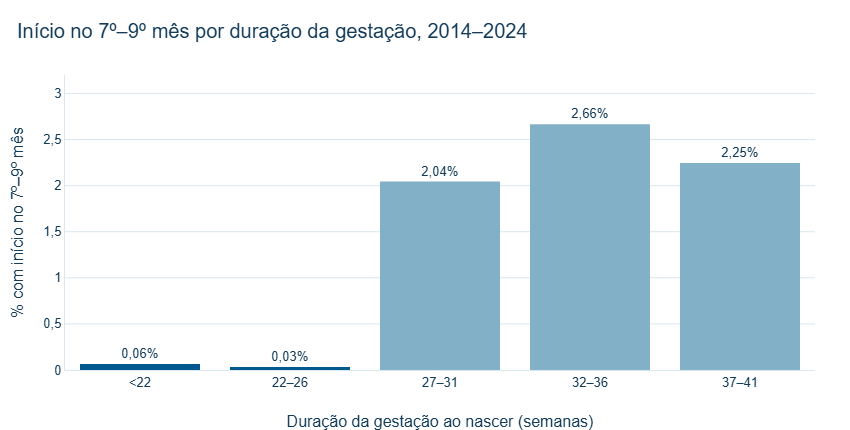

,Nascidos vivos com mês conhecido,% com início no 7º–9º mês
Semanas de gestação,,
<22,6.221,"0,06"
22–26,74.771,"0,03"
27–31,271.681,"2,04"
32–36,2.495.985,"2,66"
37–41,24.375.765,"2,25"


In [7]:
pasta_temporal = raiz / "outputs" / "temporal" / "pre_v2"
duracao = pd.read_csv(pasta_temporal / "d1_padrao_truncamento.csv")
duracao = duracao[duracao.ano == "2014-2024"].set_index("faixa_ig")
ordem = ["<22", "22-26", "27-31", "32-36", "37-41"]
duracao = duracao.loc[ordem]

rotulos_faixa = [f.replace("-", "–") for f in ordem]
pct = 100 * duracao.prop_07_09
fig = go.Figure(go.Bar(
    x=rotulos_faixa, y=pct, text=[num(v, 2) + "%" for v in pct], textposition="outside",
    marker_color=[CORES_IPT["AZUL_PRINCIPAL"]] * 2 + [CORES_IPT["AZUL_CLARO"]] * 3,
))
fig.update_xaxes(title="Duração da gestação ao nascer (semanas)")
fig.update_yaxes(title="% com início no 7º–9º mês", range=[0, 3.2])
mostrar(fig, "Início no 7º–9º mês por duração da gestação, 2014–2024", altura=430, largura=850)

display(pd.DataFrame({"Nascidos vivos com mês conhecido": duracao.n_meses_conhecidos.map(num).values,
                      "% com início no 7º–9º mês": pct.map(lambda v: num(v, 2)).values},
                     index=pd.Index(rotulos_faixa, name="Semanas de gestação")))

Entre as gestações muito curtas (menos de 27 semanas), o início no 7º–9º mês praticamente não aparece (0,06% e 0,03%). Nas gestações mais longas, ele é mais frequente, em torno de 2–2,7%.

In [8]:
candidatas = pd.read_csv(pasta_temporal / "populacoes_candidatas_pre_v2.csv")
candidatas = candidatas[candidatas.ano == "2014-2024"].set_index("alternativa").loc[["A_V1_4_9", "B_4_6", "C_4_5"]]

comparadores = pd.DataFrame({
    "Comparador": ["4º–9º mês", "4º–6º mês", "4º–5º mês"],
    "Controles de A mantidos (%)": (100 * candidatas.proporcao_mantida).map(lambda v: num(v, 1)).values,
}, index=pd.Index(["A", "B", "C"], name="Formulação"))
display(comparadores)

,Comparador,Controles de A mantidos (%)
Formulação,,
A,4º–9º mês,"100,0"
B,4º–6º mês,"86,8"
C,4º–5º mês,"73,4"


Restringir o comparador ao 4º–6º mês retira justamente a faixa 7º–9º, a mais exposta ao problema, e ainda mantém cerca de **87%** dos controles de A (onze anos agregados).

**B reduz o problema; não o elimina.** Para entrar no comparador, a gestante ainda precisa estar grávida e sem pré-natal até o 4º–6º mês. Além disso, o mês é registrado retrospectivamente, e a base contém apenas nascidos vivos. Por isso a formulação C, ainda mais restrita (4º–5º mês), é usada como **sensibilidade**: ela verifica se a conclusão depende de incluir o 6º mês no comparador.

## 5. Matriz X–T–Y

Em cada ano, depois das regras de elegibilidade, os dados são organizados em três blocos. Cada linha é um nascido vivo.

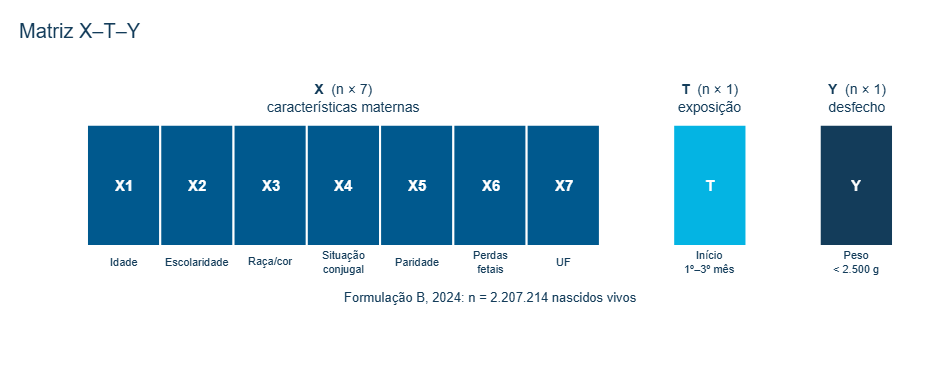

In [9]:
COLUNAS_X = ["Idade", "Escolaridade", "Raça/cor", "Situação<br>conjugal", "Paridade", "Perdas<br>fetais", "UF"]
n_b = contagens.pop_B

fig = go.Figure(go.Scatter(x=[0, 11], y=[0, 6], mode="markers", marker_opacity=0,
                           showlegend=False, hoverinfo="skip"))


def bloco_matriz(x0, x1, cor, rotulo):
    fig.add_shape(type="rect", x0=x0, x1=x1, y0=1.2, y1=4.6, fillcolor=cor, line=dict(color="white", width=2))
    fig.add_annotation(x=(x0 + x1) / 2, y=2.9, text=rotulo, showarrow=False,
                       font=dict(color="white", size=15))


for i, nome in enumerate(COLUNAS_X):
    bloco_matriz(i, i + 1, CORES_IPT["AZUL_PRINCIPAL"], f"<b>X{i + 1}</b>")
    fig.add_annotation(x=i + 0.5, y=0.75, text=nome, showarrow=False, font=dict(size=11))
bloco_matriz(8, 9, CORES_IPT["CIANO"], "<b>T</b>")
fig.add_annotation(x=8.5, y=0.75, text="Início<br>1º–3º mês", showarrow=False, font=dict(size=11))
bloco_matriz(10, 11, CORES_IPT["AZUL_ESCURO"], "<b>Y</b>")
fig.add_annotation(x=10.5, y=0.75, text="Peso<br>&lt; 2.500 g", showarrow=False, font=dict(size=11))

for x, texto in ((3.5, "<b>X</b>  (n × 7)<br>características maternas"),
                 (8.5, "<b>T</b>  (n × 1)<br>exposição"),
                 (10.5, "<b>Y</b>  (n × 1)<br>desfecho")):
    fig.add_annotation(x=x, y=5.35, text=texto, showarrow=False, font=dict(size=14))

fig.add_annotation(x=5.5, y=-0.25, showarrow=False, font=dict(size=13),
                   text=f"Formulação B, 2024: n = {num(n_b)} nascidos vivos")
fig.update_xaxes(visible=False, range=[-0.3, 11.3])
fig.update_yaxes(visible=False, range=[-0.6, 6])
mostrar(fig, "Matriz X–T–Y", altura=370, largura=950)

Abaixo, um **exemplo ilustrativo; não são registros reais**. As linhas servem apenas para mostrar a estrutura X1 … X7 | T | Y e os códigos descritos na seção 6.

In [10]:
# Exemplo ilustrativo: valores fictícios, apenas para mostrar a estrutura da matriz
matriz = pd.DataFrame({
    "X1_idade": [27, 19, 34, 23, 41],
    "X2_escolaridade": ["3", "2", "5", "3", "IGNORADO"],
    "X3_raca_cor": ["4", "4", "1", "2", "4"],
    "X4_situacao_conjugal": ["5", "1", "2", "1", "2"],
    "X5_paridade": ["1", "0", "1", "0", "1"],
    "X6_perdas_fetais": ["0", "0", "1", "IGNORADO", "2_OU_MAIS"],
    "X7_uf": ["35", "15", "31", "29", "43"],
    "T": [1, 0, 1, 1, 0],
    "Y": [0, 1, 0, 0, 0],
}, index=pd.Index([f"exemplo {i}" for i in range(1, 6)], name="Linha ilustrativa"))
display(matriz)
print(f"Dimensões em 2024 (B): X = {num(n_b)} × 7 | T = {num(n_b)} × 1 | Y = {num(n_b)} × 1")

,X1_idade,X2_escolaridade,X3_raca_cor,X4_situacao_conjugal,X5_paridade,X6_perdas_fetais,X7_uf,T,Y
Linha ilustrativa,,,,,,,,,
exemplo 1,27,3,4,5,1,0,35,1,0
exemplo 2,19,2,4,1,0,0,15,0,1
exemplo 3,34,5,1,2,1,1,31,1,0
exemplo 4,23,3,2,1,0,IGNORADO,29,1,0
exemplo 5,41,IGNORADO,4,2,1,2_OU_MAIS,43,0,0


Dimensões em 2024 (B): X = 2.207.214 × 7 | T = 2.207.214 × 1 | Y = 2.207.214 × 1


**Por que T não é "mais uma coluna" de X?** Num modelo apenas preditivo, bastaria juntar [X, T] e prever Y. Aqui a pergunta é outra: qual seria a diferença de risco se a **mesma** gestante tivesse começado o pré-natal cedo em vez de tarde. Por isso T tem papel próprio. Nos próximos notebooks, X será usado para explicar **quem** inicia cedo e, separadamente, para explicar o risco de baixo peso em cada grupo de T.

## 6. O que entra em X

São características da gestante que, em princípio, **já existiam antes** do início do pré-natal e que podem influenciar tanto o momento de início (T) quanto o peso ao nascer (Y). Elas são os **confundidores potenciais observados**.

| | Dimensão | Campo SINASC | Tipo | Codificação | Papel |
| --- | --- | --- | --- | --- | --- |
| **X1** | Idade materna | `IDADEMAE` | numérica | anos; aceita entre 10 e 59 | confundidor potencial |
| **X2** | Escolaridade | `ESCMAE2010` | categórica ordinal | 0 sem escolaridade … 5 superior completo; Ignorado | confundidor potencial |
| **X3** | Raça/cor | `RACACORMAE` | categórica | branca, preta, amarela, parda, indígena; Ignorado | confundidor potencial |
| **X4** | Situação conjugal | `ESTCIVMAE` | categórica | solteira, casada, viúva, separada, união estável; Ignorado | confundidor potencial |
| **X5** | Paridade | `PARIDADE` | binária | nulípara, multípara | confundidor potencial |
| **X6** | Perdas fetais anteriores | `QTDFILMORT` | categórica ordinal | 0, 1, 2 ou mais; Ignorado | confundidor potencial |
| **X7** | UF de residência | `CODMUNRES` (2 primeiros dígitos) | categórica | 27 UFs | confundidor potencial (acesso e contexto regional) |

- A idade é registrada no parto e serve como aproximação da idade no início da gestação.
- Ausências categóricas viram "Ignorado" e não removem registros.
- O município completo não entra em X, apenas a UF.

## 7. O que NÃO entra em X

| Variável | Campo | Quando é medida | Por que fica fora |
| --- | --- | --- | --- |
| Idade gestacional | `SEMAGESTAC`, `GESTACAO` | no parto | resulta da própria gestação; está no caminho entre pré-natal e peso e seleciona quem pode estar em cada mês (seção 4) |
| Número de consultas | `CONSPRENAT`, `CONSULTAS` | acumulado até o parto | as consultas vêm **depois** do início; são parte do efeito do pré-natal (mediadoras) |
| Tipo de parto | `PARTO` | no parto | posterior à exposição |
| Apgar | `APGAR1`, `APGAR5` | após o nascimento | desfecho neonatal, posterior à exposição |
| Índice de Kotelchuck | `KOTELCHUCK` | calculado no registro | combina o mês de início (T) com o número de consultas (mediadora) |

**Regra prática:** X descreve a gestante **antes** do início do pré-natal. Variáveis posteriores à exposição não devem ser tratadas como confundidores basais nesta análise. Elas podem ser consequência da exposição (mediadoras) ou funcionar como um filtro de quem aparece em cada grupo (variáveis de seleção). Ajustar por essas variáveis introduziria viés em vez de removê-lo.

## 8. Desenho observacional

**Não há randomização.** Ninguém sorteou o mês em que cada gestante iniciou o pré-natal. O estudo é **observacional**, com onze cortes anuais analisados separadamente (2014 a 2024).

O notebook 01 mostrou que os grupos T = 1 e T = 0 têm perfis diferentes. Por isso, a comparação é feita **após ajuste por X**: em vez de comparar diretamente as taxas de baixo peso, pergunta-se qual seria a diferença entre os dois cenários de início para gestantes **com o mesmo perfil X**, e depois se calcula a média sobre a população.

**Pergunta estimada (formulação B, em cada ano):** na população de nascidos vivos elegíveis, qual é a diferença média padronizada no risco de baixo peso, em pontos percentuais, entre iniciar o pré-natal no 1º–3º mês e iniciar no 4º–6º mês?

Para ler essa diferença como causal, quatro hipóteses são necessárias:

| Hipótese | Em termos simples | Pode ser verificada? |
| --- | --- | --- |
| **Ausência de confundimento não medido** | dado X, quem começou cedo e quem começou tarde seriam comparáveis quanto ao risco de baixo peso; nenhum fator importante (renda, tabagismo, nutrição, doenças prévias) fica fora de X | não; é uma suposição |
| **Positividade** | para cada perfil X existem gestantes nos dois grupos | sim, empiricamente (próximo notebook) |
| **Consistência** | "iniciar no 1º–3º mês" é uma condição bem definida | parcialmente; na prática, a condição reúne atendimentos de qualidade diferente |
| **Ausência de interferência** | o início do pré-natal de uma gestante não altera o desfecho de outra | não diretamente; é uma suposição plausível neste contexto |

Além disso, o SINASC registra **apenas nascidos vivos**. A conclusão vale para essa população e não se estende automaticamente a todas as gestações.

Se essas hipóteses não forem satisfeitas, o resultado deve ser lido como uma **associação ajustada**, e não como efeito causal.

## 9. População por formulação

In [11]:
populacoes = perfil.loc[ANOS, ["n_analitico_A", "n_B", "n_C", "pct_precoce_A", "pct_precoce_B"]].copy()
totais = populacoes[["n_analitico_A", "n_B", "n_C"]].sum()
assert totais.to_dict() == {"n_analitico_A": 28_194_211, "n_B": 27_533_362, "n_C": 26_860_501}

tabela = pd.DataFrame({
    "N — A": populacoes.n_analitico_A.map(num),
    "N — B (principal)": populacoes.n_B.map(num),
    "N — C": populacoes.n_C.map(num),
    "% T = 1 em A": populacoes.pct_precoce_A.map(lambda v: num(v, 2)),
    "% T = 1 em B": populacoes.pct_precoce_B.map(lambda v: num(v, 2)),
}).rename_axis("Ano")
tabela.loc["Total 2014–2024"] = [num(totais.n_analitico_A), num(totais.n_B), num(totais.n_C), "—", "—"]
display(tabela)

,N — A,N — B (principal),N — C,% T = 1 em A,% T = 1 em B
Ano,,,,,
2014,2.691.119,2.615.773,2.538.604,"78,55","80,82"
2015,2.745.846,2.673.272,2.599.919,"79,40","81,56"
2016,2.626.594,2.560.827,2.492.767,"80,27","82,33"
2017,2.695.676,2.630.828,2.562.927,"81,02","83,01"
2018,2.734.473,2.672.423,2.606.245,"81,74","83,63"
2019,2.645.383,2.586.743,2.524.898,"82,40","84,27"
2020,2.535.311,2.476.058,2.415.861,"82,48","84,45"
2021,2.481.267,2.425.844,2.371.495,"83,91","85,83"
2022,2.397.626,2.344.255,2.291.516,"84,18","86,10"


- **A, B e C são populações diferentes**, e cada uma responde a uma pergunta diferente (um estimando diferente). O grupo T = 1 é o mesmo; o que muda é com quem ele é comparado.
- **B é a análise principal**, com 27.533.362 nascidos vivos em onze anos (2.207.214 em 2024).
- **C não "corrige" B.** C restringe ainda mais o comparador e verifica se a conclusão depende de incluir o 6º mês. Diferenças entre B e C refletem populações diferentes, e não o erro de uma delas.
- **A permanece como referência histórica**, com a limitação temporal descrita na seção 4.

## 10. Encerramento

- **Notebook 01:** entendemos os dados, isto é, volume, qualidade, desfecho, exposição, perfil materno e evolução 2014–2024.
- **Notebook 02:** definimos **quem entra na análise** (populações A, B e C), **qual pergunta será estimada** (início no 1º–3º mês versus 4º–6º mês, formulação B) e **com quais variáveis** a comparação será ajustada (X1–X7).

**Próximo notebook:** escore de propensão, balanceamento das covariáveis e suporte comum (*overlap*) entre os grupos T = 1 e T = 0.